# 04 · Consumer Duty guardrails

We keep the same SVD model, but add a **rules layer** on top that re-ranks each customer's list. Each rule maps to part of the Consumer Duty:

| Rule | What it does | Consumer Duty link |
|---|---|---|
| **R1** | Customers flagged as in financial difficulty never see restricted items (credit, gambling offers, crypto, stocks & shares) | Avoid foreseeable harm |
| **R2** | Credit and risky investments are never recommended just because "similar customers liked them". They only appear after a basic affordability check, max one per list | Products & services |
| **R3** | Flagged customers always get at least one supportive feature (budgeting, savings, debt advice, gambling block) | Consumer support |
| **R4** | Every recommendation comes with a plain-English reason | Consumer understanding |

The rules are in `src/recsys.py → apply_guardrails()`.

> This is a portfolio exercise, not legal or compliance advice. Real firms design these controls with compliance teams.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.recsys import *

plt.rcParams["figure.figsize"] = (8, 4.5)
TEAL, CORAL, GREY = "#1f6f8b", "#e07a5f", "#9aa5ab"

In [2]:
import json
from surprise import SVD
from surprise.model_selection import train_test_split

customers, catalogue, engagement = load_tables()
flags = get_flags(make_database(customers, catalogue, engagement))
best_params = json.load(open("../results/model_selection.json"))["best_params"]

data = to_surprise(engagement)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
svd = SVD(**best_params).fit(trainset)
ranked = rank_unseen(svd, trainset, catalogue["item_id"].tolist())

naive = top_n(ranked)
guarded_full = apply_guardrails(ranked, catalogue, flags)
guarded = {u: [i for i, _, _ in v] for u, v in guarded_full.items()}

## 1. Before vs after for one flagged customer

In [3]:
cat = catalogue.set_index("item_id")
example = flags[flags["financial_difficulty_flag"] == 1]["customer_id"].iloc[0]
print("Customer:", example, "| flagged because:", flags.set_index("customer_id").loc[example, "flag_reasons"])
before = pd.DataFrame({"naive top 5": [cat.loc[i, "item_name"] for i in naive[example]]})
after = pd.DataFrame([{"guarded top 5": cat.loc[i, "item_name"], "reason shown to customer": r}
                      for i, _, r in guarded_full[example]])
pd.concat([before, after], axis=1)

Customer: U00006 | flagged because: missed payment; high gambling spend; high-cost credit use;


,naive top 5,guarded top 5,reason shown to customer
0,Credit card,Cashback: supermarket,Cashback where customers with similar spending...
1,Cashback: supermarket,Cashback: electronics,Cashback where customers with similar spending...
2,Cashback: electronics,Round-ups,A free tool that can help you stay on top of y...
3,Round-ups,Salary sorter,A free tool that can help you stay on top of y...
4,Salary sorter,Cash ISA,"A simple way to build savings, protected up to..."


## 2. Harm: naive vs guarded

In [4]:
naive_harm = harm_report(naive, catalogue, flags)
guarded_harm = harm_report(guarded, catalogue, flags)
harm = pd.DataFrame({"naive": naive_harm, "guarded": guarded_harm}).round(1)
harm

,naive,guarded
% of flagged customers shown a restricted item,92.7,0.0
% of flagged customers' slots that are restricted,37.2,0.0
% of flagged customers shown a supportive feature,43.8,100.0
% of all customers shown credit/risky investment without passing affordability,54.6,0.0


## 3. What did it cost in engagement?

Guardrails remove items some customers *would* have engaged with, so ranking accuracy should fall a little. How much?

In [5]:
p_n, r_n = precision_recall_at_k(naive, testset)
p_g, r_g = precision_recall_at_k(guarded, testset)
tradeoff = pd.DataFrame({"precision@5": [p_n, p_g], "recall@5": [r_n, r_g]}, index=["naive", "guarded"]).round(3)
tradeoff["relative change in precision"] = ["", f"{(p_g - p_n) / p_n:+.0%}"]
tradeoff

,precision@5,recall@5,relative change in precision
naive,0.165,0.617,
guarded,0.133,0.500,-20%


A fairer view: split by customer group. Most of the "lost" engagement comes from **flagged** customers no longer being shown the credit and gambling offers they would have activated — the same activations that led to missed payments in notebook 01.

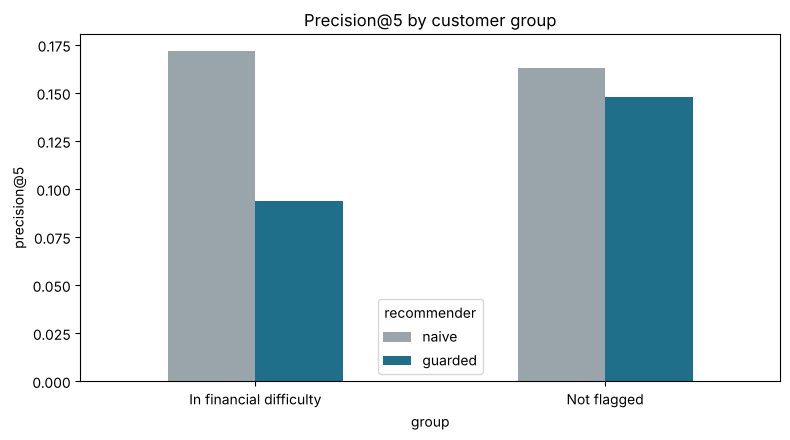

recommender,naive,guarded
group,,
In financial difficulty,0.172,0.094
Not flagged,0.163,0.148


In [6]:
from collections import defaultdict
flag_set = set(flags.loc[flags["financial_difficulty_flag"] == 1, "customer_id"])
rows = []
for group, members in [("Not flagged", lambda u: u not in flag_set), ("In financial difficulty", lambda u: u in flag_set)]:
    ts = [t for t in testset if members(t[0])]
    for name, recs in [("naive", naive), ("guarded", guarded)]:
        p, r = precision_recall_at_k(recs, ts)
        rows.append({"group": group, "recommender": name, "precision@5": p})
by_group = pd.DataFrame(rows).pivot(index="group", columns="recommender", values="precision@5")[["naive", "guarded"]]
by_group.plot.bar(color=[GREY, TEAL], rot=0); plt.title("Precision@5 by customer group"); plt.ylabel("precision@5")
plt.tight_layout(); plt.savefig("../images/precision_by_group.png", dpi=120, bbox_inches="tight"); plt.show()
by_group.round(3)

## 4. The headline chart

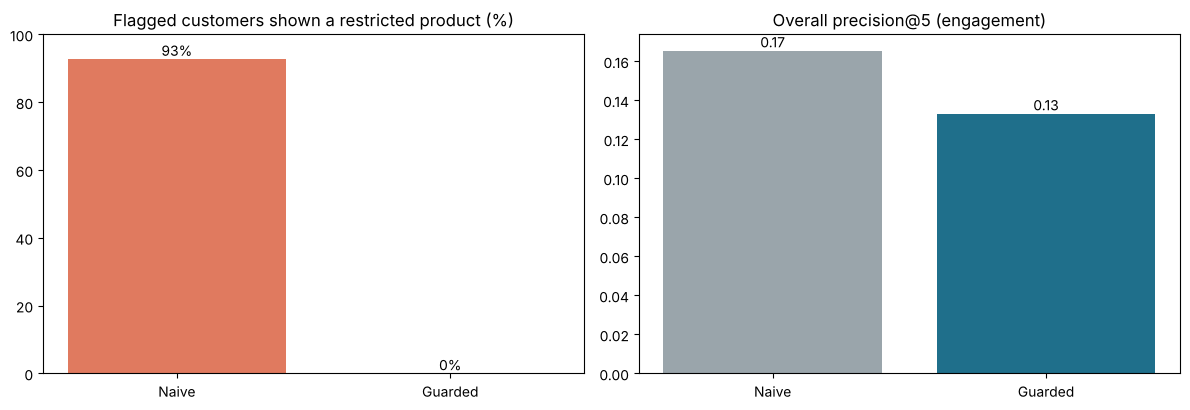

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
k1 = "% of flagged customers shown a restricted item"
k2 = "% of flagged customers shown a supportive feature"
axes[0].bar(["Naive", "Guarded"], [naive_harm[k1], guarded_harm[k1]], color=[CORAL, TEAL])
axes[0].set_title("Flagged customers shown a restricted product (%)"); axes[0].set_ylim(0, 100)
axes[1].bar(["Naive", "Guarded"], [p_n, p_g], color=[GREY, TEAL])
axes[1].set_title("Overall precision@5 (engagement)")
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f" if ax is axes[1] else "%.0f%%")
plt.tight_layout(); plt.savefig("../images/headline.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. Export for Power BI

A flat table of every recommendation with the reason, the customer's flag status and flag reasons — ready to load into Power BI for a monitoring dashboard (the Duty expects firms to **monitor outcomes**, not just write policies).

In [8]:
f = flags.set_index("customer_id")
out = pd.DataFrame([{"customer_id": u, "rank": k + 1, "item_id": i, "item_name": cat.loc[i, "item_name"],
                     "item_type": cat.loc[i, "item_type"], "risk_level": cat.loc[i, "risk_level"],
                     "predicted_score": round(s, 2), "reason": r,
                     "financial_difficulty_flag": int(f.loc[u, "financial_difficulty_flag"]),
                     "flag_reasons": f.loc[u, "flag_reasons"]}
                    for u, v in guarded_full.items() for k, (i, s, r) in enumerate(v)])
out.to_csv("../results/guarded_recommendations.csv", index=False)
json.dump({"naive": {k: float(v) for k, v in naive_harm.items()}, "guarded": {k: float(v) for k, v in guarded_harm.items()},
           "precision@5": {"naive": p_n, "guarded": p_g}, "recall@5": {"naive": r_n, "guarded": r_g}},
          open("../results/guardrail_results.json", "w"), indent=2)
out.head(10)

,customer_id,rank,item_id,item_name,item_type,risk_level,predicted_score,reason,financial_difficulty_flag,flag_reasons
0,U00505,1,O07,Cashback: electronics,offer,none,3.31,Cashback where customers with similar spending...,0,
1,U00505,2,O08,Cashback: streaming,offer,none,2.85,Cashback where customers with similar spending...,0,
2,U00505,3,F05,Salary sorter,feature,none,2.62,Customers who use the app like you do find thi...,0,
3,U00505,4,O09,Cashback: cinema,offer,none,2.52,Cashback where customers with similar spending...,0,
4,U00505,5,F11,Gambling block,feature,none,2.44,Customers who use the app like you do find thi...,0,
5,U04921,1,O01,Cashback: supermarket,offer,none,3.57,Cashback where customers with similar spending...,1,persistent overdraft; missed payment; high gam...
6,U04921,2,F06,Spending insights,feature,none,3.35,A free tool that can help you stay on top of y...,1,persistent overdraft; missed payment; high gam...
7,U04921,3,F05,Salary sorter,feature,none,3.22,A free tool that can help you stay on top of y...,1,persistent overdraft; missed payment; high gam...
8,U04921,4,O03,Cashback: restaurants,offer,none,3.22,Cashback where customers with similar spending...,1,persistent overdraft; missed payment; high gam...
9,U04921,5,F02,Round-ups,feature,none,3.14,A free tool that can help you stay on top of y...,1,persistent overdraft; missed payment; high gam...


## Conclusions

1. **An accurate recommender can still be harmful.** Optimising engagement taught the model to push debt and gambling to the customers most likely to be hurt by them.
2. **A simple, reviewable rules layer** removed that exposure completely, and guaranteed every flagged customer sees a supportive tool.
3. **The cost is modest and lands in the right place:** most of the precision drop comes from flagged customers no longer being shown products linked to missed payments.
4. **Engagement is the wrong success measure on its own.** A real firm would track outcome metrics too (arrears, complaints, use of support tools) — which is what the Power BI export is for.

### Limitations
- Synthetic data; the flag thresholds and affordability check are simplified stand-ins.
- Financial data only shows **financial resilience**. FCA vulnerability also covers health, life events and capability, which usually come from customer conversations, not transactions.
- Using difficulty flags to *protect* people is very different from using them to *target* people — data protection and fairness reviews would be needed in a real firm.

### Next steps
- Add outcome-aware training (penalise items linked to later arrears) instead of only post-filtering
- Fairness checks across age and region
- A Power BI dashboard on `results/guarded_recommendations.csv`